# CP2 — Beyond Joel: Advisor-Score Regressor Experiments

Executes `plan.md`. The earlier notebook (`improve_regressor.ipynb`) is the frozen pre-Joel record;
everything new happens here. Context lives in `fatak_notes.md` (Joel's results, tried-and-rejected
list, numbers to beat).

Structure (mirrors `plan.md`):
- **Phase 0** — foundation: Joel's 75 engineered features (`joel_features.py`), LightGBM with his
  settings, k-fold out-of-fold evaluation, and the **baseline every experiment must beat**
- **Phase A** — feature experiments: A1 dispersion/beyond-nearest, A2 spectral (DCT), A3 assignment commute
- **Phase B** — model experiments: B1 quantile certification, B2 boundary weighting, B3 stacking, B4 pseudo-labels
- **Phase C** — latent-space assessment (PCA/NMF, small autoencoder) + written verdict

In [1]:
# Bootstrap - runs both on Colab and locally in the ps2 repo.
#
# Colab clones the course repo into /content. Locally we reuse the clone that
# ./setup_data.sh puts in data/cp2-repo (gitignored: ~70 MB of course data that
# is not ours to commit). Either way we chdir into it, because utils_public.py
# resolves "datasets/..." and "assets/..." relative to the working directory.
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
COURSE_REPO = "https://github.com/decode-mit/2155-CP2-2026.git"


def _ps2_root(start):
    """Walk up from `start` to the ps2 repo root (the dir holding environment.yml)."""
    d = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(d, "environment.yml")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise RuntimeError(f"could not find the ps2 repo root above {start}")
        d = parent


if IN_COLAB:
    COURSE_ROOT = "/content/2155-CP2-2026"
    SUBMISSION_DIR = "/content/submissions"
    PS2_ROOT = "/content"
else:
    # Re-running this cell is safe: cwd is then the course clone, and walking
    # up from data/cp2-repo still lands on the ps2 root.
    PS2_ROOT = _ps2_root(os.getcwd())
    COURSE_ROOT = os.path.join(PS2_ROOT, "data", "cp2-repo")
    SUBMISSION_DIR = os.path.join(PS2_ROOT, "submissions")

if not os.path.isdir(COURSE_ROOT):
    subprocess.run(["git", "clone", "--depth", "1", COURSE_REPO, COURSE_ROOT], check=True)

os.chdir(COURSE_ROOT)
sys.path.insert(0, COURSE_ROOT)
sys.path.insert(0, PS2_ROOT)  # for joel_features.py at the ps2 repo root
os.makedirs(SUBMISSION_DIR, exist_ok=True)

from utils_public import *

print(f"course data: {COURSE_ROOT}")
print(f"submissions: {SUBMISSION_DIR}")

course data: /Users/fb/repos/2.156-ps2/data/cp2-repo
submissions: /Users/fb/repos/2.156-ps2/submissions


## Load data
500k grids; each advisor labeled 5k of them (1%). `ADVISOR_NAMES` indexes columns of `ratings`.

In [2]:
import numpy as np
import pandas as pd

grids = load_grids()
ratings = np.load("datasets/scores.npy")
ADVISOR_NAMES = ["Wellness", "Tax", "Transportation", "Business"]

print(grids.shape, ratings.shape)
print("labels per advisor:", (~np.isnan(ratings)).sum(axis=0))

(500000, 7, 7) (500000, 4)
labels per advisor: [5000 5000 5000 5000]


# Phase 0 — Foundation

## CV experiment harness

Upgrade over the old notebook's single 75/25 split: **5-fold out-of-fold (OOF) predictions on all
5,000 labels, repeated over 3 shuffle seeds**. Every grid is predicted by a model that never trained
on it, every label is used for evaluation, and the seed-to-seed spread shows how much a "win" could
be luck (Joel's logs: the same model's approvals moved 523→550 between shuffles — single splits
flatter winners).

Primary metric unchanged: **recall@98p** — the share of truly valid grids (score ≥ 0.75) the model
certifies while the certified pool stays ≥ 98% truly valid. 0 = certifies nothing at that trust
level; 1 = perfect ranker. Also recorded: yield@98p, PR-AUC (stabler tiebreaker), OOF R² (sanity).

- `feature_fn` / `model_fn` can be a single callable or a dict `{advisor_name: callable}` —
  per-advisor lineups are first-class (Joel's final models differ per advisor).
- `seeds=(0,)` for quick iteration; the default `(0, 1, 2)` for any number you intend to quote.
- One experiment ≈ 4 advisors × 3 seeds × 5 folds = 60 fits (a few minutes with LightGBM).
- `results_table_cv()` pivots mean recall@98p (±spread available via `results_table_cv("recall_spread")`).

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, r2_score
from sklearn.model_selection import KFold

RESULTS_CV = []  # one row per (experiment, advisor)
VALID_THRESHOLD = 0.75
SHUFFLE_SEEDS = (0, 1, 2)


def certify_at_precision(preds, y_true, target=0.98):
    """Walk down the prediction ranking as far as cumulative precision allows.

    Returns (recall, yield_frac) at the deepest depth where the certified pool is still
    >= target precision. recall: certified truly-valid / all truly-valid (0..1, 1 = perfect
    ranker). yield_frac: certified / all grids (ceiling = the valid fraction, ~0.25).
    """
    order = np.argsort(-preds)
    valid = (y_true[order] >= VALID_THRESHOLD)
    cum_valid = np.cumsum(valid)
    cum_precision = cum_valid / np.arange(1, len(valid) + 1)
    ok = np.where(cum_precision >= target)[0]
    if not ok.size:
        return 0.0, 0.0
    deepest = ok[-1]
    return cum_valid[deepest] / valid.sum(), (deepest + 1) / len(valid)


def oof_predict(X, y, model_fn, n_splits=5, seed=0):
    """Out-of-fold predictions: every row predicted by a model fitted without it."""
    oof = np.empty(len(y), dtype=np.float64)
    for train, test in KFold(n_splits, shuffle=True, random_state=seed).split(X):
        model = model_fn()
        model.fit(X[train], y[train])
        oof[test] = model.predict(X[test])
    return oof


def _per_advisor(fn_or_dict, advisor_name):
    return fn_or_dict[advisor_name] if isinstance(fn_or_dict, dict) else fn_or_dict


def run_experiment_cv(name, feature_fn, model_fn, seeds=SHUFFLE_SEEDS, plot=True):
    """OOF-evaluate one recipe per advisor over several fold shuffles; log mean recall@98p.

    feature_fn and model_fn: a callable, or a dict {advisor_name: callable} for per-advisor lineups.
    The scatter shows the first seed's OOF predictions; the title reports the mean over seeds and
    the min-max spread.
    """
    if plot:
        fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharex=True, sharey=True)
    for advisor in range(4):
        aname = ADVISOR_NAMES[advisor]
        grids_subset, y = select_rated_subset(grids, ratings[:, advisor])
        X = _per_advisor(feature_fn, aname)(grids_subset)
        mfn = _per_advisor(model_fn, aname)

        recalls, yields, oof_first = [], [], None
        for seed in seeds:
            oof = oof_predict(X, y, mfn, seed=seed)
            r, yl = certify_at_precision(oof, y)
            recalls.append(r)
            yields.append(yl)
            if oof_first is None:
                oof_first = oof
        spread = max(recalls) - min(recalls)
        RESULTS_CV.append({
            "experiment": name, "advisor": aname,
            "recall_at_98p": float(np.mean(recalls)), "recall_spread": float(spread),
            "yield_at_98p": float(np.mean(yields)),
            "pr_auc": average_precision_score(y >= VALID_THRESHOLD, oof_first),
            "r2_oof": r2_score(y, oof_first),
        })

        if plot:
            ax = axes[advisor]
            ax.scatter(y, oof_first, s=3, c="#DC267F")
            ax.plot([0, 1], [0, 1], c="k", linewidth=2)
            ax.axvline(VALID_THRESHOLD, c="#444444", linewidth=1, linestyle="--")
            ax.set_title(f"{aname}\nrecall@98p = {np.mean(recalls):.2f} (±{spread/2:.2f})")
            ax.spines[["right", "top"]].set_visible(False)
    if plot:
        fig.suptitle(f"{name}  —  OOF predictions, seed {seeds[0]}")
        axes[0].set_ylabel("Predicted (OOF)")
        for ax in axes:
            ax.set_xlabel("Actual")
        plt.tight_layout()
        plt.show()


def results_table_cv(metric="recall_at_98p"):
    """Experiments x advisors for one metric ('recall_at_98p', 'recall_spread', 'yield_at_98p',
    'pr_auc', 'r2_oof'), with a mean column; best experiment at the bottom."""
    df = pd.DataFrame(RESULTS_CV).drop_duplicates(subset=["experiment", "advisor"], keep="last")
    table = df.pivot(index="experiment", columns="advisor", values=metric)[ADVISOR_NAMES]
    table["mean"] = table.mean(axis=1)
    return table.sort_values("mean")

## Feature encodings

- `engineered` — Joel's 75 rotation-invariant features (`joel_features.py`, ported with attribution):
  counts (5), adjacency incl. diagonals (30), distance-to-nearest (20), clusters (10), edge/centre (10)
- `engineered_plus_onehot` — + the 245 one-hot cells (position); Joel's adopted Wellness inputs
- `onehot_plus_adjacency` — the old notebook's best encoding, kept as a cross-notebook sanity anchor

Phase A adds new encodings here, each as `engineered` + one new group.

In [4]:
import joel_features as jf


def engineered(grids):
    return jf.engineered(grids)  # (n, 75)


def engineered_plus_onehot(grids):
    return np.hstack([jf.engineered(grids), jf.onehot(grids)])  # (n, 320)


def adjacency_counts(grids):
    """Old notebook's 15 side-by-side pair counts (kept only for the sanity anchor)."""
    n = grids.shape[0]
    pairs = np.zeros((n, 5, 5), dtype=int)
    h_a, h_b = grids[:, :, :-1], grids[:, :, 1:]
    v_a, v_b = grids[:, :-1, :], grids[:, 1:, :]
    for a, b in [(h_a, h_b), (v_a, v_b)]:
        lo = np.minimum(a, b).reshape(n, -1)
        hi = np.maximum(a, b).reshape(n, -1)
        np.add.at(pairs, (np.arange(n)[:, None], lo, hi), 1)
    iu = np.triu_indices(5)
    return pairs[:, iu[0], iu[1]]


def onehot_plus_adjacency(grids):
    return np.hstack([jf.onehot(grids), adjacency_counts(grids)])

## The baseline to beat

Joel's final recipe re-measured in *our* harness, so every later experiment is compared under an
identical procedure (no cross-protocol conversion arguments): LightGBM with his exact settings
(600 trees, lr 0.03, 31 leaves, 0.8 row/column subsampling) on the 75 engineered features —
plus the one-hot cells for Wellness, his adopted variant. (His Transportation ensemble and
Business feature groups are *not* reproduced here; this is the strong-and-simple core.)

**Sanity anchor:** his dev-set numbers convert to roughly recall@98p ≈ 0.56 (Wellness, with
one-hot) / 0.81 (Tax) / 0.73 (Transportation) / 0.89 (Business). Our baseline should land in that
neighbourhood — if it's wildly off, the harness is miswired, not the model.

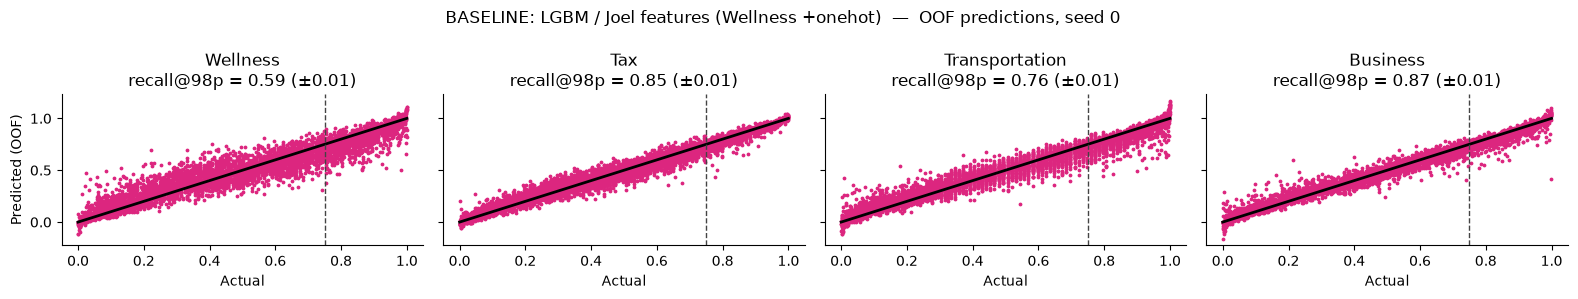

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [5]:
import lightgbm as lgb

# Joel's exact settings (joel_dev validity.py GBM_PARAMS; set by hand, never tuned on data)
GBM_PARAMS = {
    "n_estimators": 600,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "random_state": 0,
    "verbose": -1,
}


def lgbm():
    return lgb.LGBMRegressor(**GBM_PARAMS)


BASELINE_FEATURES = {"Wellness": engineered_plus_onehot, "Tax": engineered,
                     "Transportation": engineered, "Business": engineered}

run_experiment_cv("BASELINE: LGBM / Joel features (Wellness +onehot)", BASELINE_FEATURES, lgbm)
results_table_cv()

## Cross-notebook sanity anchor

Our old best (HistGB on onehot+adjacency) through the new CV harness. Expect recall@98p in the
same ballpark as the old notebook's single-split numbers (~0.17 / 0.59 / 0.09 / 0.43) — likely a
touch higher and steadier, since OOF uses all 5,000 labels. Confirms old and new results live on
one scale; the gap to the baseline above is what Joel's features buy.

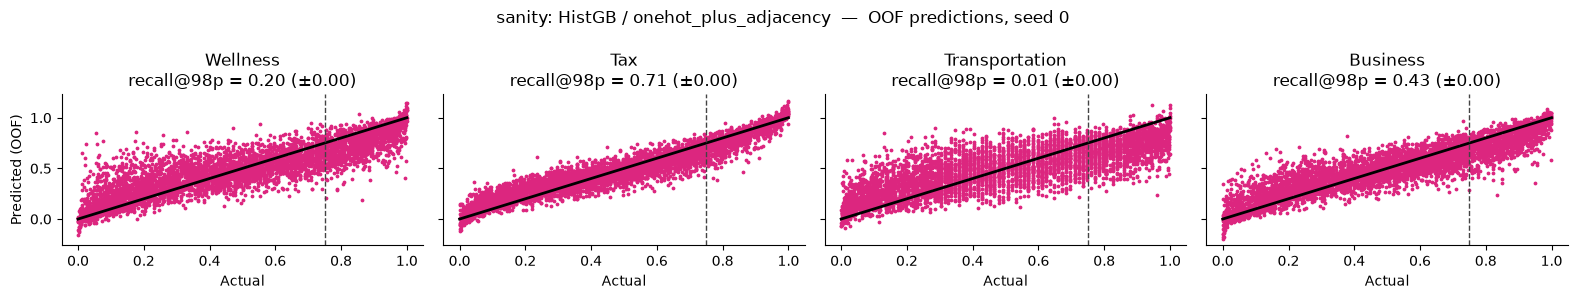

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
sanity: HistGB / onehot_plus_adjacency,0.203363,0.713445,0.009639,0.430544,0.339248
BASELINE: LGBM / Joel features (Wellness +onehot),0.585535,0.852661,0.757965,0.872191,0.767088


In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor

run_experiment_cv("sanity: HistGB / onehot_plus_adjacency", onehot_plus_adjacency,
                  lambda: HistGradientBoostingRegressor(random_state=0), seeds=(0,))
results_table_cv()

# Phase A — Feature experiments

*(next: A1 dispersion & beyond-nearest distances · A2 low-frequency DCT · A3 assignment-based
commute cost — each evaluated as `engineered` + the new group, per advisor, vs. the baseline)*

# Phase B — Model experiments

*(next: B1 quantile certification · B2 boundary-weighted training · B3 heterogeneous stacking ·
B4 pseudo-labeling with the 495k unlabeled grids)*

# Phase C — Latent-space assessment

*(next: C1 PCA/NMF latents from all 500k grids · C2 small conv autoencoder — then the written
verdict on whether representation learning is the right tool here)*